# Iris Flower Classification using K-Nearest Neighbors

**Goal:** Build a classification model that predicts the species of an iris flower from its measurements.

**Dataset:** Iris (150 samples, 4 features, 3 classes)
**Algorithm:** K-Nearest Neighbors (KNN)
**Tools:** Python, pandas, matplotlib, seaborn, scikit-learn

## Step 1: Import the libraries
These libraries cover data handling (pandas, numpy), plotting (matplotlib, seaborn), and the dataset itself (scikit-learn).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from matplotlib.colors import ListedColormap

os.makedirs("images", exist_ok=True)

print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)

scikit-learn: 1.9.0
pandas: 3.0.5
numpy: 2.5.1


## Step 2: Load the Iris dataset

The dataset comes built into scikit-learn, so no download is needed. I converted it into a pandas table and added a readable species name column.

In [2]:
iris = load_iris()

df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = iris.target

df["species_name"] = df["species"].map({0: "setosa", 1: "versicolor", 2: "virginica"})

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,species_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## Step 3: Understand the data structure

The dataset has 150 samples, 4 features, and 3 classes with 50 samples each, so the classes are perfectly balanced. There are no missing values, so no cleaning is needed.

In [3]:
print("Shape:", df.shape)
print("Features:", iris.feature_names)
print("Classes:", list(iris.target_names))
print("\nMissing values:\n", df.isnull().sum())
print("\nSamples per class:\n", df["species_name"].value_counts())

Shape: (150, 6)
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]

Missing values:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
species_name         0
dtype: int64

Samples per class:
 species_name
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## Step 4: Summary statistics

The four features have different ranges. For example, sepal length goes up to about 7.9 cm while petal width reaches only 2.5 cm. This is why feature scaling will matter later for KNN.

In [4]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


## Step 5: Visualize the classes

Setosa forms a clearly separate cluster, especially in petal length and petal width. Versicolor and Virginica overlap slightly, so this is where the model is most likely to make mistakes.

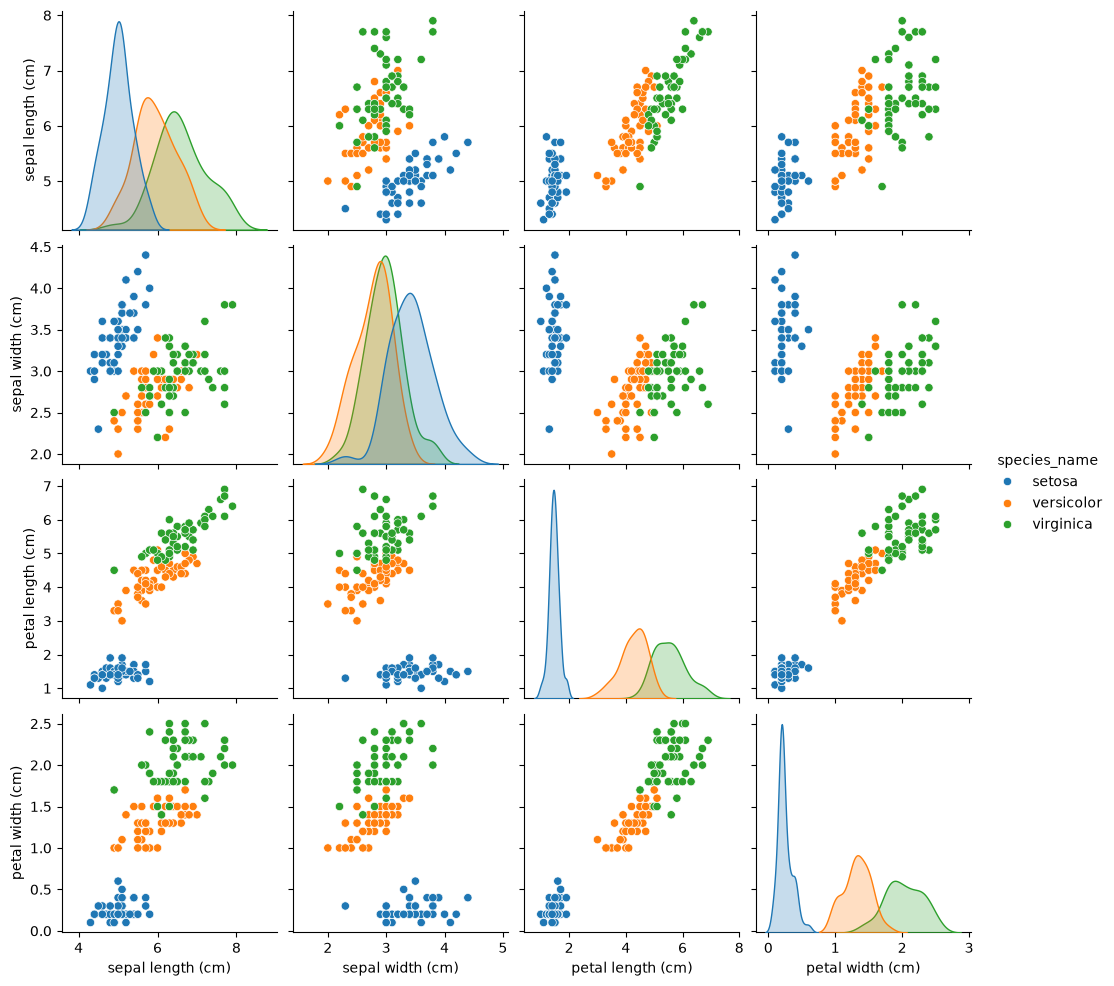

In [5]:
sns.pairplot(df, hue="species_name", vars=iris.feature_names)
plt.savefig("images/pairplot.png")
plt.show()

## Step 6: Separate features and labels

X holds the four measurements the model learns from, and y holds the correct species it should predict.

In [6]:
X = df[iris.feature_names]
y = df["species"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (150, 4)
y shape: (150,)


## Step 7: Split into training and test sets

I used an 80/20 split. The model learns from 80% of the data and is tested on the remaining 20%, which it has never seen. I set random_state so the results are the same every time, and stratify so each species is represented equally in both sets.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

## Step 8: Check the split

The training set has 120 samples and the test set has 30. Each species appears 40 times in training and 10 times in testing, so the classes stay balanced.

In [8]:
print("Training samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])

print("\nTraining class counts:")
print(y_train.value_counts())

print("\nTest class counts:")
print(y_test.value_counts())

Training samples: 120
Test samples: 30

Training class counts:
species
0    40
2    40
1    40
Name: count, dtype: int64

Test class counts:
species
0    10
2    10
1    10
Name: count, dtype: int64


## Step 9: Scale the features

The four features have different ranges, and KNN relies on distance, so larger-valued features would dominate. I used StandardScaler to give every feature a mean of 0 and a standard deviation of 1. The scaler learns from the training data only, then is applied to the test data, so no information leaks from the test set.

In [9]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Step 10: Check the scaling

After scaling, the training features have a mean of about 0 and a standard deviation of about 1. The test set values are close to this but not exact, which is expected because the scaler only learned from the training data.

In [34]:
print("Before scaling (first flower):")
print(X_train.iloc[0].values)

print("\nAfter scaling (first flower):")
print(X_train_scaled[0])

print("\nTraining mean after scaling:")
print(X_train_scaled.mean(axis=0).round(2))

print("\nTraining std after scaling:")
print(X_train_scaled.std(axis=0).round(2))

print("\nTest mean after scaling:", X_test_scaled.mean(axis=0).round(2))
print("Test std after scaling:", X_test_scaled.std(axis=0).round(2))

Before scaling (first flower):
[4.4 2.9 1.4 0.2]

After scaling (first flower):
[-1.72156775 -0.33210111 -1.34572231 -1.32327558]

Training mean after scaling:
[-0.  0.  0.  0.]

Training std after scaling:
[1. 1. 1. 1.]

Test mean after scaling: [ 0.01  0.1  -0.03 -0.04]
Test std after scaling: [0.93 0.85 0.99 1.  ]


## Step 11: Build and train the KNN model

KNN doesn't learn rules the way other algorithms do. It stores the training data, and when it sees a new flower it finds the 5 closest training flowers and takes a majority vote. I started with K=5 as a reasonable default and will tune it later.

In [11]:
model = KNeighborsClassifier(n_neighbors=5)

model.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## Step 12: Predict on the test set
The model predicted a species for each of the 30 test flowers, which it has never seen before. The first ten predictions are compared with the true species below.

In [12]:
predictions = model.predict(X_test_scaled)

print("First 10 predictions: ", predictions[:10])
print("First 10 true labels: ", y_test.values[:10])

First 10 predictions:  [0 2 1 1 0 1 0 0 2 1]
First 10 true labels:  [0 2 1 1 0 1 0 0 2 1]


## Step 13: Check the accuracy

The model's accuracy on the test set is shown below. Accuracy is a good first check here because the classes are balanced, but later I will look deeper with a confusion matrix, precision, recall, and F1 score.

In [13]:
accuracy = accuracy_score(y_test, predictions)

print("Accuracy:", accuracy)
print("Accuracy as percent:", round(accuracy * 100, 2), "%")

Accuracy: 0.9333333333333333
Accuracy as percent: 93.33 %


## Step 14: Find the best value of K

K controls how many neighbors vote. A very small K is sensitive to noise (overfitting), and a very large K becomes too generic (underfitting). I tested K from 1 to 25 using 5-fold cross-validation on the training data only, so the test set stays untouched.

In [14]:
k_values = range(1, 26)
error_rates = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train_scaled, y_train, cv=5)
    error = 1 - scores.mean()
    error_rates.append(error)

print("Done. Tested", len(error_rates), "values of K")

Done. Tested 25 values of K


In [15]:
for k, e in zip(k_values, error_rates):
    print(f"K={k:2d}  error={e*100:.2f}%")

K= 1  error=5.83%
K= 2  error=4.17%
K= 3  error=4.17%
K= 4  error=4.17%
K= 5  error=3.33%
K= 6  error=3.33%
K= 7  error=4.17%
K= 8  error=4.17%
K= 9  error=4.17%
K=10  error=3.33%
K=11  error=4.17%
K=12  error=3.33%
K=13  error=5.00%
K=14  error=4.17%
K=15  error=5.00%
K=16  error=4.17%
K=17  error=4.17%
K=18  error=5.83%
K=19  error=5.83%
K=20  error=6.67%
K=21  error=6.67%
K=22  error=7.50%
K=23  error=7.50%
K=24  error=9.17%
K=25  error=10.83%


## Step 15: Plot error rate against K

Error is 5.83% at K=1, where the model is sensitive to individual noisy points. It drops to 3.33% to 4.17% for most values between K=2 and K=12, stays at or below 5.00% up to K=17, and then climbs steadily to 10.83% at K=25 as the neighbourhood gets too broad and the model underfits. The differences between nearby K values are small (one training flower out of 120 is about 0.83 percentage points), so I read the curve as a stable region rather than a sharp optimum.

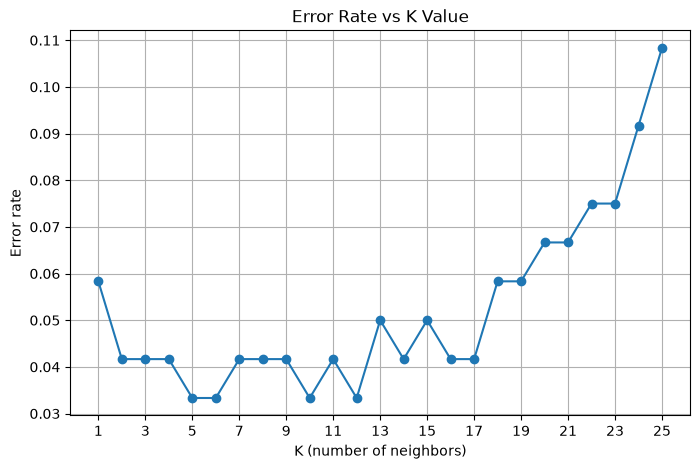

In [16]:
plt.figure(figsize=(8, 5))
plt.plot(k_values, error_rates, marker="o")
plt.title("Error Rate vs K Value")
plt.xlabel("K (number of neighbors)")
plt.ylabel("Error rate")
plt.xticks(range(1, 26, 2))
plt.grid(True)
plt.savefig("images/k_vs_error.png")
plt.show()

## Step 16: Pick the best K

K=5, 6, 10 and 12 all reached the lowest cross-validation error of 3.33%. Because they tie, I chose K=5: it is the smallest of the tied values, sits inside the stable region of the curve, and matches the default I started with. Smaller K is also cheaper to compute and less likely to blur class boundaries.

In [17]:
best_error = min(error_rates)
tied_ks = [k for k, e in zip(k_values, error_rates) if e == best_error]

print("Lowest error rate:", round(best_error, 4))
print("K values that tie for the lowest error:", tied_ks)

best_k = 5  # chosen: smallest-neighbourhood tie inside the stable region, matches the default
print("Chosen K:", best_k)

Lowest error rate: 0.0333
K values that tie for the lowest error: [5, 6, 10, 12]
Chosen K: 5


## Step 17: Confirm the final model

Cross-validation selected K=5, which is the same value I used initially, so the final model is identical to the first one. I refit it explicitly as `final_model` and confirm the test accuracy is unchanged.

In [18]:
final_model = KNeighborsClassifier(n_neighbors=best_k)
final_model.fit(X_train_scaled, y_train)

final_predictions = final_model.predict(X_test_scaled)
final_accuracy = accuracy_score(y_test, final_predictions)

print("Initial model (K=5) accuracy:", round(accuracy * 100, 2), "%")
print(f"Final model (K={best_k}) accuracy:", round(final_accuracy * 100, 2), "%")

Initial model (K=5) accuracy: 93.33 %
Final model (K=5) accuracy: 93.33 %


## Step 18: Confusion matrix

The model classified 28 of 30 test flowers correctly. All Setosa and Versicolor flowers were correct. The only 2 mistakes were Virginica flowers predicted as Versicolor.

In [19]:
cm = confusion_matrix(y_test, final_predictions)
print(cm)

[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]


## Step 19: Confusion matrix heatmap

The dark diagonal shows most predictions are correct. The single off-diagonal square (2 Virginica predicted as Versicolor) is consistent with the overlap seen in the pairplot.

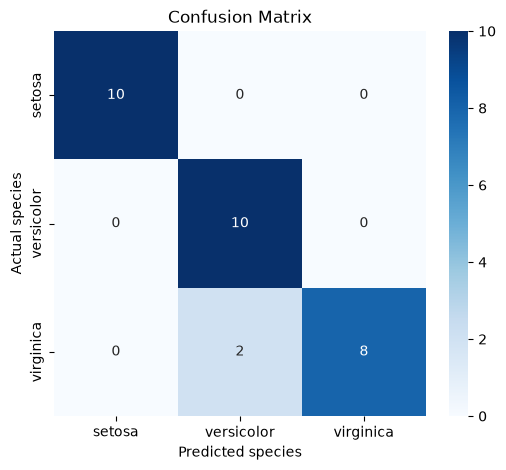

In [20]:
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=iris.target_names,
            yticklabels=iris.target_names)
plt.xlabel("Predicted species")
plt.ylabel("Actual species")
plt.title("Confusion Matrix")
plt.savefig("images/confusion_matrix.png")
plt.show()

## Step 20: Precision, recall and F1 score

Setosa scored a perfect 1.00 on all metrics. Versicolor has recall 1.00 but precision 0.83, because 2 Virginica flowers were wrongly labelled Versicolor. Virginica has precision 1.00 but recall 0.80, because those same 2 flowers were missed. The overall accuracy is 0.93 and the macro F1 score is 0.93.

In [21]:
report = classification_report(y_test, final_predictions,
                               target_names=iris.target_names)
print(report)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



## Step 21: Compare KNN with other algorithms

To check whether KNN is a good choice, I trained a Decision Tree and Logistic Regression on the same training data and compared their test accuracy.All three models score identically here, but a 30-sample test set is too small to separate them. Step 24 repeats the comparison over 20 random splits.

In [22]:
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train_scaled, y_train)
tree_predictions = tree_model.predict(X_test_scaled)
tree_accuracy = accuracy_score(y_test, tree_predictions)

logistic_model = LogisticRegression(max_iter=200)
logistic_model.fit(X_train_scaled, y_train)
logistic_predictions = logistic_model.predict(X_test_scaled)
logistic_accuracy = accuracy_score(y_test, logistic_predictions)

print("KNN accuracy:", round(final_accuracy * 100, 2), "%")
print("Decision Tree accuracy:", round(tree_accuracy * 100, 2), "%")
print("Logistic Regression accuracy:", round(logistic_accuracy * 100, 2), "%")

KNN accuracy: 93.33 %
Decision Tree accuracy: 93.33 %
Logistic Regression accuracy: 93.33 %


## Step 22: Predict a brand-new flower

I typed in measurements for a flower that is not in the dataset. The model scales it the same way as the training data and predicts its species.

In [23]:
new_flower = pd.DataFrame([[6.15, 2.85, 4.75, 1.55]], columns=iris.feature_names)
assert not (df[iris.feature_names].values == new_flower.values).all(axis=1).any()

new_flower_scaled = scaler.transform(new_flower)
prediction = final_model.predict(new_flower_scaled)
print("Predicted species:", iris.target_names[prediction[0]])

Predicted species: versicolor


## Step 23: Analyse the model's mistakes

The model made only 2 mistakes out of 30. Both were Virginica flowers predicted as Versicolor (rows 138 and 134). Their measurements are printed below.

In [24]:
mistake_mask = final_predictions != y_test.values

mistakes = X_test[mistake_mask]

print("Measurements of the misclassified flowers:")
print(mistakes)

print("\nActual species:   ", iris.target_names[y_test[mistake_mask].values])
print("Predicted species:", iris.target_names[final_predictions[mistake_mask]])

Measurements of the misclassified flowers:
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
138                6.0               3.0                4.8               1.8
134                6.1               2.6                5.6               1.4

Actual species:    ['virginica' 'virginica']
Predicted species: ['versicolor' 'versicolor']


## Step 23a: Compare the mistakes with the average of each species

Neither mistake looks like a typical Virginica flower, because each one has a mix of Versicolor-like and Virginica-like measurements.
- Flower 138 (petal length 4.8 cm, petal width 1.8 cm): its petal length is closer to the Versicolor average (4.26 cm) than the Virginica average (5.55 cm), but its petal width is closer to Virginica (average 2.03 cm vs 1.33 cm).
- Flower 134 (petal length 5.6 cm, petal width 1.4 cm): its petal length matches the Virginica average, but its petal width of 1.4 cm is almost exactly the Versicolor average. Its sepal length (6.1 cm) and sepal width (2.6 cm) are also closer to Versicolor.

In [25]:
average_flowers = df.groupby("species_name")[iris.feature_names].mean()

print("Average measurements per species:")
print(average_flowers.round(2))

Average measurements per species:
              sepal length (cm)  sepal width (cm)  petal length (cm)  \
species_name                                                           
setosa                     5.01              3.43               1.46   
versicolor                 5.94              2.77               4.26   
virginica                  6.59              2.97               5.55   

              petal width (cm)  
species_name                    
setosa                    0.25  
versicolor                1.33  
virginica                 2.03  


## Step 23b: Where the mistakes sit on the plot

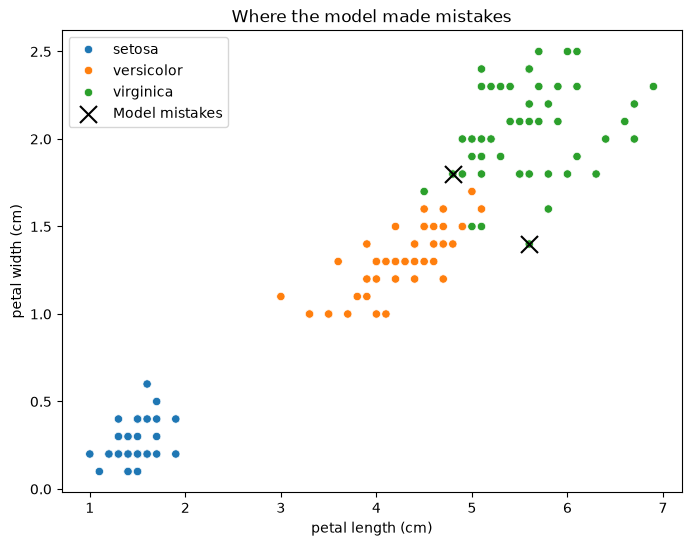

In [35]:
plt.figure(figsize=(8, 6))

sns.scatterplot(data=df, x="petal length (cm)", y="petal width (cm)",
                hue="species_name")

plt.scatter(mistakes["petal length (cm)"], mistakes["petal width (cm)"],
            color="black", marker="x", s=150, label="Model mistakes")

plt.title("Where the model made mistakes")
plt.legend()
plt.savefig("images/mistakes_plot.png")
plt.show()

Observation: Both mistakes (black X marks) lie in the zone where the Versicolor and Virginica clusters meet. One sits at the lower edge of the Virginica cluster, close to the Versicolor points, and the other sits below the main Virginica group because of its low petal width. Setosa is far from both, so it was never at risk.

## Step 23c: How the nearest neighbours voted

In [27]:
mistake_scaled = X_test_scaled[mistake_mask]

distances, neighbor_positions = final_model.kneighbors(mistake_scaled)

for i in range(len(mistake_scaled)):
    neighbor_species = y_train.values[neighbor_positions[i]]
    print("Mistake", i + 1, "- its 5 nearest neighbours were:",
          iris.target_names[neighbor_species])

Mistake 1 - its 5 nearest neighbours were: ['virginica' 'versicolor' 'versicolor' 'virginica' 'versicolor']
Mistake 2 - its 5 nearest neighbours were: ['versicolor' 'versicolor' 'virginica' 'versicolor' 'virginica']


Observation: For both mistakes, the 5 nearest neighbours were split 3 to 2 in favour of Versicolor (3 Versicolor, 2 Virginica). The model lost a close vote on genuinely ambiguous flowers. This is consistent with ambiguous flowers rather than a pipeline problem.

## Step 24: Test with 20 different random splits

A single 30-sample test set can be lucky or unlucky. I repeated the whole process 20 times with different random splits and compared the average accuracy of each model.

KNN: mean 96.00% | std 3.43% | min 86.67% | max 100.00%
Decision Tree: mean 95.67% | std 3.51% | min 86.67% | max 100.00%
Logistic Regression: mean 96.50% | std 3.57% | min 86.67% | max 100.00%


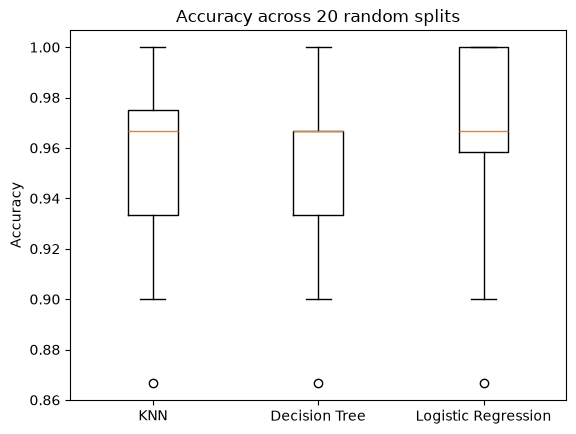

In [33]:
knn_scores = []
tree_scores = []
logistic_scores = []

for seed in range(20):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, random_state=seed, stratify=y
    )

    sc = StandardScaler()
    X_tr_scaled = sc.fit_transform(X_tr)
    X_te_scaled = sc.transform(X_te)

    knn = KNeighborsClassifier(n_neighbors=5)
    knn.fit(X_tr_scaled, y_tr)
    knn_scores.append(accuracy_score(y_te, knn.predict(X_te_scaled)))

    tree = DecisionTreeClassifier(random_state=42)
    tree.fit(X_tr_scaled, y_tr)
    tree_scores.append(accuracy_score(y_te, tree.predict(X_te_scaled)))

    logistic = LogisticRegression(max_iter=200)
    logistic.fit(X_tr_scaled, y_tr)
    logistic_scores.append(accuracy_score(y_te, logistic.predict(X_te_scaled)))

for name, scores in [("KNN", knn_scores),
                     ("Decision Tree", tree_scores),
                     ("Logistic Regression", logistic_scores)]:
    print(f"{name}: mean {np.mean(scores)*100:.2f}% | std {np.std(scores)*100:.2f}% | "
          f"min {np.min(scores)*100:.2f}% | max {np.max(scores)*100:.2f}%")

plt.boxplot([knn_scores, tree_scores, logistic_scores],
            tick_labels=["KNN", "Decision Tree", "Logistic Regression"])
plt.ylabel("Accuracy")
plt.title("Accuracy across 20 random splits")
plt.savefig("images/model_comparison.png")
plt.show()

### Observation: 
The mean accuracies span 95.67% to 96.50%, a gap of 0.83 points, while the split-to-split standard deviation is about 3.4 to 3.6 points. The differences between models are much smaller than the variation from which flowers land in the test set, so I cannot rank them on this evidence. All three share the same worst case (86.67%) and best case (100%).

## Step 25: Test different KNN settings

I compared two ways of weighting neighbors (equal vs closer-counts-more) and two distance measures (euclidean vs manhattan) using 5-fold cross-validation on the training data.

In [29]:
for weights in ["uniform", "distance"]:
    for metric in ["euclidean", "manhattan"]:
        knn = KNeighborsClassifier(n_neighbors=5, weights=weights, metric=metric)
        scores = cross_val_score(knn, X_train_scaled, y_train, cv=5)
        print(weights, "+", metric, "->", round(scores.mean() * 100, 2), "%")

uniform + euclidean -> 96.67 %
uniform + manhattan -> 95.83 %
distance + euclidean -> 96.67 %
distance + manhattan -> 95.83 %


## Observation: 
Using 5-fold cross-validation on the training data, uniform and distance weighting gave identical accuracy. Euclidean distance scored 96.67% and Manhattan distance 95.83%. That gap is under 1 percentage point, equal to one training flower out of 120, so I treat the settings as equivalent on this dataset and keep the default (uniform weights, Euclidean distance).

## Step 26: Test the effect of scaling

Iris features are all in centimetres, so scaling changes little. To show why scaling matters, I multiplied sepal width by 1000, as if it were recorded in different units, and compared KNN with and without scaling.

In [30]:
X_train_big = X_train.copy()
X_test_big = X_test.copy()
X_train_big["sepal width (cm)"] = X_train_big["sepal width (cm)"] * 1000
X_test_big["sepal width (cm)"] = X_test_big["sepal width (cm)"] * 1000

model_a = KNeighborsClassifier(n_neighbors=5)
model_a.fit(X_train, y_train)
acc_a = accuracy_score(y_test, model_a.predict(X_test))

model_b = KNeighborsClassifier(n_neighbors=5)
model_b.fit(X_train_big, y_train)
acc_b = accuracy_score(y_test, model_b.predict(X_test_big))

big_scaler = StandardScaler()
X_train_big_scaled = big_scaler.fit_transform(X_train_big)
X_test_big_scaled = big_scaler.transform(X_test_big)

model_c = KNeighborsClassifier(n_neighbors=5)
model_c.fit(X_train_big_scaled, y_train)
acc_c = accuracy_score(y_test, model_c.predict(X_test_big_scaled))

print("Original units, no scaling:", round(acc_a * 100, 2), "%")
print("Sepal width x1000, no scaling:", round(acc_b * 100, 2), "%")
print("Sepal width x1000, with scaling:", round(acc_c * 100, 2), "%")

Original units, no scaling: 100.0 %
Sepal width x1000, no scaling: 66.67 %
Sepal width x1000, with scaling: 93.33 %


### Observation: 
On the original Iris data, unscaled KNN scored 100% and scaled KNN 93.33%. That is a 2-flower difference on 30 samples, which is within noise, so I do not read it as evidence that scaling hurts. Multiplying sepal width by 1000 dropped unscaled accuracy to 66.67% because that feature dominated every distance, and scaling restored it to 93.33%. The takeaway: scaling is harmless on Iris but protects KNN when features are on very different scales.

## Step 27: Decision boundary plot

To see how KNN separates the species, I trained a KNN on just two features (petal length and petal width) and coloured the plot by the species predicted at each point. This is for visualisation only. The main model uses all four features. The two-feature model scored higher than the four-feature model on this one split, but that gap is within noise on 30 samples and is not evidence that fewer features are better.

In [31]:
X_two = df[["petal length (cm)", "petal width (cm)"]]

X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(
    X_two, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler_2 = StandardScaler()
X_train_2_scaled = scaler_2.fit_transform(X_train_2)
X_test_2_scaled = scaler_2.transform(X_test_2)

model_2 = KNeighborsClassifier(n_neighbors=5)
model_2.fit(X_train_2_scaled, y_train_2)

accuracy_2 = accuracy_score(y_test_2, model_2.predict(X_test_2_scaled))
print("Two-feature model accuracy:", round(accuracy_2 * 100, 2), "%")

Two-feature model accuracy: 96.67 %


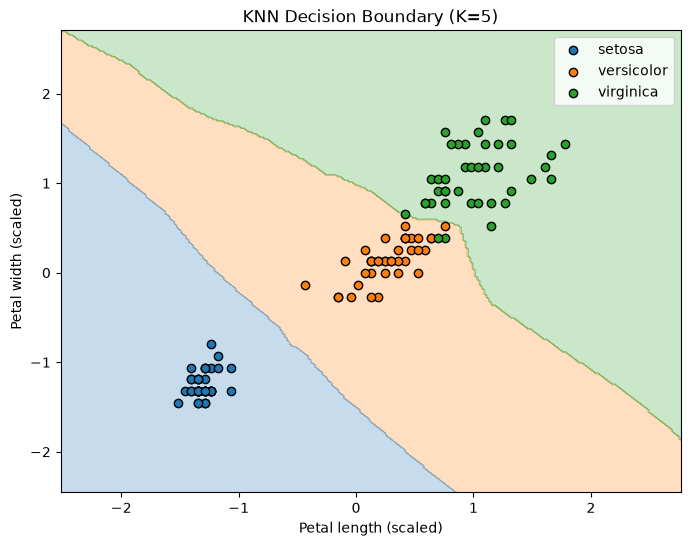

In [32]:
x_min = X_train_2_scaled[:, 0].min() - 1
x_max = X_train_2_scaled[:, 0].max() + 1
y_min = X_train_2_scaled[:, 1].min() - 1
y_max = X_train_2_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

grid_points = np.c_[xx.ravel(), yy.ravel()]
grid_predictions = model_2.predict(grid_points)
grid_predictions = grid_predictions.reshape(xx.shape)

colors = ["tab:blue", "tab:orange", "tab:green"]

plt.figure(figsize=(8, 6))

plt.contourf(xx, yy, grid_predictions, alpha=0.25,
             cmap=ListedColormap(colors))

for class_number in range(3):
    mask = y_train_2.values == class_number
    plt.scatter(X_train_2_scaled[mask, 0], X_train_2_scaled[mask, 1],
                color=colors[class_number], edgecolor="black",
                label=iris.target_names[class_number])

plt.title("KNN Decision Boundary (K=5)")
plt.xlabel("Petal length (scaled)")
plt.ylabel("Petal width (scaled)")
plt.legend()
plt.savefig("images/decision_boundary.png")
plt.show()

## Conclusion

- Built a KNN classifier on the Iris dataset using a stratified 80/20 train-test split, with StandardScaler fitted on training data only to avoid data leakage.
- Tuned K with 5-fold cross-validation on the training set. K=5 gave the lowest error (3.3%).
- Test accuracy was 93.33% (28 of 30). The only 2 errors were Virginica flowers predicted as Versicolor, both with mixed measurements in the overlap zone, and both lost a 3-to-2 neighbour vote.
- Over 20 random splits, average accuracy was 96.0% (KNN), 95.67% (Decision Tree) and 96.5% (Logistic Regression), so the models perform comparably.
- Different weighting and distance settings made almost no difference on this dataset.
- Scaling did not change accuracy much on the original Iris data, but it prevents a large drop when one feature has a very different scale.
- A decision boundary plot using only petal length and petal width showed three distinct regions, with a smooth Setosa boundary and a jagged Versicolor-Virginica boundary. That two-feature model scored 96.67% on the test set.

**Limitations:** The test set has only 30 samples, so single-split results vary noticeably. Iris is also a small, easy dataset, so these results may not carry over to harder problems.